Import all required libraries

In [40]:
import sys
import xgboost

print("Python path:", sys.executable)
print("XGBoost version:", xgboost.__version__)

Python path: f:\web3geeks-ai-bootcamp\.venv\Scripts\python.exe
XGBoost version: 3.4.1


Load the Telco Customer Churn dataset

In [41]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Data splitting and preprocessing
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Model evaluation
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("All libraries imported successfully!")

All libraries imported successfully!


these libraries support data preparation, model training, visualization and model evaluation.

Explore the dataset

In [42]:
# Dataset URL
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

# Load dataset
df = pd.read_csv(url)

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display first five rows
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [43]:
# Dataset information
print("Dataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Churn distribution
print("\nChurn Distribution:")
print(df["Churn"].value_counts())

# Dataset statistics
print("\nNumerical Summary:")
display(df.describe())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null 

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Cleaning the dataset

In [44]:
# Convert TotalCharges into numeric values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Remove customerID because it is an identifier, not a useful predictor
df = df.drop(columns=["customerID"])

# Convert Churn into binary values
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

# Check cleaning results
print("Cleaned dataset shape:", df.shape)

print("\nMissing values after conversion:")
print(df.isnull().sum().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

Cleaned dataset shape: (7043, 20)

Missing values after conversion:
11

Churn distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


Separate features and target

In [45]:
# Features
X = df.drop(columns=["Churn"])

# Target
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (7043, 19)
Target shape: (7043,)


Split the dataset into training and testing sets

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining churners:", y_train.sum())
print("Testing churners:", y_test.sum())

Training features: (5634, 19)
Testing features: (1409, 19)

Training churners: 1495
Testing churners: 374


Identify numerical and categorical columns

In [47]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\AL-SAEED\AppData\Local\Temp\ipykernel_6452\1263442432.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


Create the preprocessing function

In [48]:
def create_preprocessor():

    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features)
        ]
    )

    return preprocessor

print("Preprocessing function created successfully!")

Preprocessing function created successfully!


Define the four machine learning models

In [49]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ),

    "Random Forest (min_samples_leaf=10)": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=10,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        random_state=42,
        eval_metric="logloss",
        n_jobs=1
    )
}

print("Four models are ready:")
for model_name in models:
    print("-", model_name)

Four models are ready:
- Logistic Regression
- Random Forest
- Random Forest (min_samples_leaf=10)
- XGBoost


Create the model evaluation function

In [50]:
def evaluate_model(model, X_train, X_test, y_train, y_test):

    pipeline = Pipeline(steps=[
        ("preprocessor", create_preprocessor()),
        ("model", model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predictions
    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)

    # Predicted probabilities
    train_prob = pipeline.predict_proba(X_train)[:, 1]
    test_prob = pipeline.predict_proba(X_test)[:, 1]

    # Evaluation metrics
    results = {
        "Confusion Matrix": confusion_matrix(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_test_pred, zero_division=0),
        "Train ROC AUC": roc_auc_score(y_train, train_prob),
        "Test ROC AUC": roc_auc_score(y_test, test_prob)
    }

    return pipeline, results, test_prob

Train and evaluate all four models

In [51]:
trained_models = {}
model_results = {}
test_probabilities = {}

for model_name, model in models.items():

    print("\nEvaluating:", model_name)

    pipeline, results, test_prob = evaluate_model(
        model,
        X_train,
        X_test,
        y_train,
        y_test
    )

    trained_models[model_name] = pipeline
    model_results[model_name] = results
    test_probabilities[model_name] = test_prob

    print("Confusion Matrix:")
    print(results["Confusion Matrix"])

    print(f"Precision: {results['Precision']:.4f}")
    print(f"Recall: {results['Recall']:.4f}")
    print(f"F1 Score: {results['F1 Score']:.4f}")
    print(f"Train ROC AUC: {results['Train ROC AUC']:.4f}")
    print(f"Test ROC AUC: {results['Test ROC AUC']:.4f}")


Evaluating: Logistic Regression


Confusion Matrix:
[[926 109]
 [165 209]]
Precision: 0.6572
Recall: 0.5588
F1 Score: 0.6040
Train ROC AUC: 0.8493
Test ROC AUC: 0.8419

Evaluating: Random Forest
Confusion Matrix:
[[920 115]
 [197 177]]
Precision: 0.6062
Recall: 0.4733
F1 Score: 0.5315
Train ROC AUC: 0.9999
Test ROC AUC: 0.8171

Evaluating: Random Forest (min_samples_leaf=10)
Confusion Matrix:
[[944  91]
 [185 189]]
Precision: 0.6750
Recall: 0.5053
F1 Score: 0.5780
Train ROC AUC: 0.9013
Test ROC AUC: 0.8437

Evaluating: XGBoost
Confusion Matrix:
[[935 100]
 [179 195]]
Precision: 0.6610
Recall: 0.5214
F1 Score: 0.5830
Train ROC AUC: 0.9053
Test ROC AUC: 0.8423


Perform 5-fold stratified cross-validation

In [52]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = {}

for model_name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", create_preprocessor()),
        ("model", model)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    cv_results[model_name] = {
        "CV ROC AUC Mean": scores.mean(),
        "CV ROC AUC Std": scores.std()
    }

    print(f"\n{model_name}")
    print("Fold scores:", np.round(scores, 4))
    print(f"Mean ROC AUC: {scores.mean():.4f}")
    print(f"Standard Deviation: {scores.std():.4f}")


Logistic Regression
Fold scores: [0.8479 0.8252 0.8419 0.8629 0.8529]
Mean ROC AUC: 0.8461
Standard Deviation: 0.0125

Random Forest
Fold scores: [0.8152 0.8056 0.8258 0.8149 0.841 ]
Mean ROC AUC: 0.8205
Standard Deviation: 0.0121

Random Forest (min_samples_leaf=10)
Fold scores: [0.8425 0.8339 0.8447 0.8554 0.86  ]
Mean ROC AUC: 0.8473
Standard Deviation: 0.0093

XGBoost
Fold scores: [0.8396 0.8307 0.8415 0.8555 0.8558]
Mean ROC AUC: 0.8446
Standard Deviation: 0.0097


Plot ROC curves

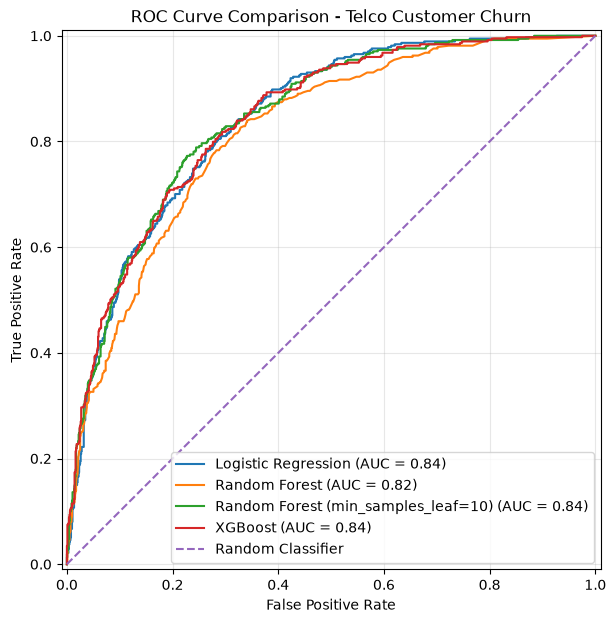

In [53]:
plt.figure(figsize=(10, 7))

for model_name, probabilities in test_probabilities.items():

    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name,
        ax=plt.gca()
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison - Telco Customer Churn")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Model comparison table

In [54]:
comparison_data = []

for model_name in models:

    comparison_data.append({
        "Model": model_name,
        "Test F1": model_results[model_name]["F1 Score"],
        "Test ROC AUC": model_results[model_name]["Test ROC AUC"],
        "CV ROC AUC Mean": cv_results[model_name]["CV ROC AUC Mean"],
        "CV ROC AUC Std": cv_results[model_name]["CV ROC AUC Std"]
    })

comparison_df = pd.DataFrame(comparison_data)

comparison_df = comparison_df.sort_values(
    by="CV ROC AUC Mean",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

,Model,Test F1,Test ROC AUC,CV ROC AUC Mean,CV ROC AUC Std
0,Random Forest (min_samples_leaf=10),0.5780,0.8437,0.8473,0.0093
1,Logistic Regression,0.6040,0.8419,0.8461,0.0125
2,XGBoost,0.5830,0.8423,0.8446,0.0097
3,Random Forest,0.5315,0.8171,0.8205,0.0121


Select the best-performing model

In [55]:
best_model_name = comparison_df.iloc[0]["Model"]

best_pipeline = trained_models[best_model_name]

print("Selected model:", best_model_name)

print(
    "Cross-validation ROC AUC:",
    round(cv_results[best_model_name]["CV ROC AUC Mean"], 4)
)

print(
    "Cross-validation standard deviation:",
    round(cv_results[best_model_name]["CV ROC AUC Std"], 4)
)

Selected model: Random Forest (min_samples_leaf=10)
Cross-validation ROC AUC: 0.8473
Cross-validation standard deviation: 0.0093


Identify the top five important features

In [56]:
preprocessor = best_pipeline.named_steps["preprocessor"]
best_estimator = best_pipeline.named_steps["model"]

feature_names = preprocessor.get_feature_names_out()

if hasattr(best_estimator, "feature_importances_"):

    importance_values = best_estimator.feature_importances_

elif hasattr(best_estimator, "coef_"):

    importance_values = np.abs(best_estimator.coef_[0])

else:
    raise ValueError("Selected model does not provide feature importance.")

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

top_5_features = feature_importance.sort_values(
    by="Importance",
    ascending=False
).head(5)

print("Top 5 important features:")
display(top_5_features.reset_index(drop=True).round(4))

Top 5 important features:


,Feature,Importance
0,num__tenure,0.1415
1,cat__Contract_Month-to-month,0.1238
2,num__TotalCharges,0.1131
3,num__MonthlyCharges,0.0688
4,cat__OnlineSecurity_No,0.0662


final business conclusion

In [57]:
best_row = comparison_df.iloc[0]

print("FINAL MODEL COMPARISON SUMMARY")
print("=" * 45)

print("Selected model:", best_model_name)

print(f"Test F1 Score: {best_row['Test F1']:.4f}")
print(f"Test ROC AUC: {best_row['Test ROC AUC']:.4f}")
print(f"CV ROC AUC Mean: {best_row['CV ROC AUC Mean']:.4f}")
print(f"CV ROC AUC Std: {best_row['CV ROC AUC Std']:.4f}")

print("\nTop five important features:")
for feature in top_5_features["Feature"]:
    print("-", feature)

print("\nBusiness Recommendation:")
print(
    "The selected model can help the telecom company identify "
    "customers who are more likely to churn. Management can use "
    "these predictions to prioritize customer retention efforts, "
    "investigate important churn drivers, and design targeted "
    "retention offers."
)


FINAL MODEL COMPARISON SUMMARY
Selected model: Random Forest (min_samples_leaf=10)
Test F1 Score: 0.5780
Test ROC AUC: 0.8437
CV ROC AUC Mean: 0.8473
CV ROC AUC Std: 0.0093

Top five important features:
- num__tenure
- cat__Contract_Month-to-month
- num__TotalCharges
- num__MonthlyCharges
- cat__OnlineSecurity_No

Business Recommendation:
The selected model can help the telecom company identify customers who are more likely to churn. Management can use these predictions to prioritize customer retention efforts, investigate important churn drivers, and design targeted retention offers.


In [58]:
comparison_df.to_csv(
    "week2_model_comparison_results.csv",
    index=False
)

print("Comparison results saved successfully!")

Comparison results saved successfully!
